# Bank mijozlarining ketishi (Churn) prognozi
**Maqsad:** `Exited` ehtimolligini bashorat qilish. **Metrika:** ROC AUC.

Tarkib:
1) Kutubxonalar va ma'lumot yuklash
2) EDA (grafiklar)
3) Feature engineering
4) Cross-validation: LightGBM, XGBoost, CatBoost  
5) ROC egri chizig'i, Confusion matrix, Feature importance
6) Blending va `submission.csv`

In [ ]:
!pip -q install lightgbm xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.5 MB/s eta 0:00:00


In [4]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, classification_report)
import lightgbm as lgb, xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42

## 1. Ma'lumotlarni yuklash
Fayllar Colab'ga yuklangan bo'lmasa, `train.csv`, `test.csv`, `sample_submission.csv` ni tanlashingiz so'raladi.

In [4]:
import os
import pandas as pd

need = ['train.csv', 'test.csv', 'sample_submission.csv']
if not all(os.path.exists(f) for f in need):
    from google.colab import files
    files.upload()

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sub = pd.read_csv('sample_submission.csv')
print('train:', train.shape, '| test:', test.shape)
train.head()

train: (15000, 14) | test: (10000, 13)


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


## 2. EDA

In [5]:
display(train.describe().T)
print('Yo\'qolgan qiymatlar (train):', train.isna().sum().sum(), '| (test):', test.isna().sum().sum())
print('Dublikatlar:', train.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
id,15000.0,7.499500e+03,4.330271e+03,0.00,3.749750e+03,7499.50,1.124925e+04,1.499900e+04
CustomerId,15000.0,1.579454e+07,1.268495e+07,156715.07,1.563435e+07,15689471.50,1.575682e+07,1.569172e+09
CreditScore,15000.0,6.578568e+02,7.267874e+01,431.00,6.020000e+02,661.00,7.070000e+02,8.500000e+02
Age,15000.0,3.771013e+01,8.144880e+00,18.00,3.200000e+01,37.00,4.200000e+01,7.200000e+01
Tenure,15000.0,5.018667e+00,2.787407e+00,0.00,3.000000e+00,5.00,7.000000e+00,1.000000e+01
Balance,15000.0,4.233811e+04,5.970305e+04,0.00,0.000000e+00,0.00,1.096363e+05,1.879115e+05
NumOfProducts,15000.0,1.590533e+00,5.258220e-01,1.00,1.000000e+00,2.00,2.000000e+00,5.000000e+00
HasCrCard,15000.0,7.791333e-01,4.148446e-01,0.00,1.000000e+00,1.00,1.000000e+00,1.000000e+00
IsActiveMember,15000.0,4.960000e-01,5.000007e-01,0.00,0.000000e+00,0.00,1.000000e+00,1.000000e+00
EstimatedSalary,15000.0,1.169441e+05,4.604749e+04,11.58,8.264433e+04,122449.42,1.557030e+05,8.851208e+05


Yo'qolgan qiymatlar (train): 0 | (test): 0
Dublikatlar: 0


/tmp/ipykernel_14668/1996728754.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Exited', data=train, ax=ax[0], palette='Set2')


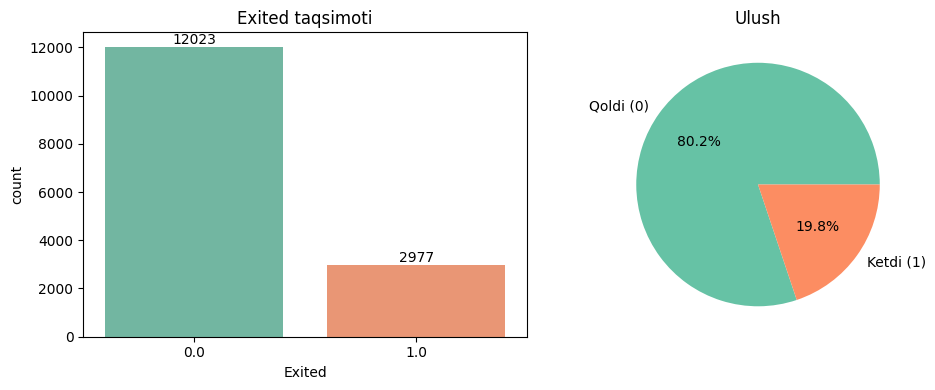

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Maqsad o'zgaruvchisi taqsimoti
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
vc = train.Exited.value_counts()
sns.countplot(x='Exited', data=train, ax=ax[0], palette='Set2')
ax[0].set_title('Exited taqsimoti')
for i, v in enumerate(vc.sort_index()):
    ax[0].text(i, v, str(v), ha='center', va='bottom')
ax[1].pie(vc.sort_index(), labels=['Qoldi (0)', 'Ketdi (1)'], autopct='%1.1f%%', colors=sns.color_palette('Set2'))
ax[1].set_title('Ulush')
plt.tight_layout(); plt.show()

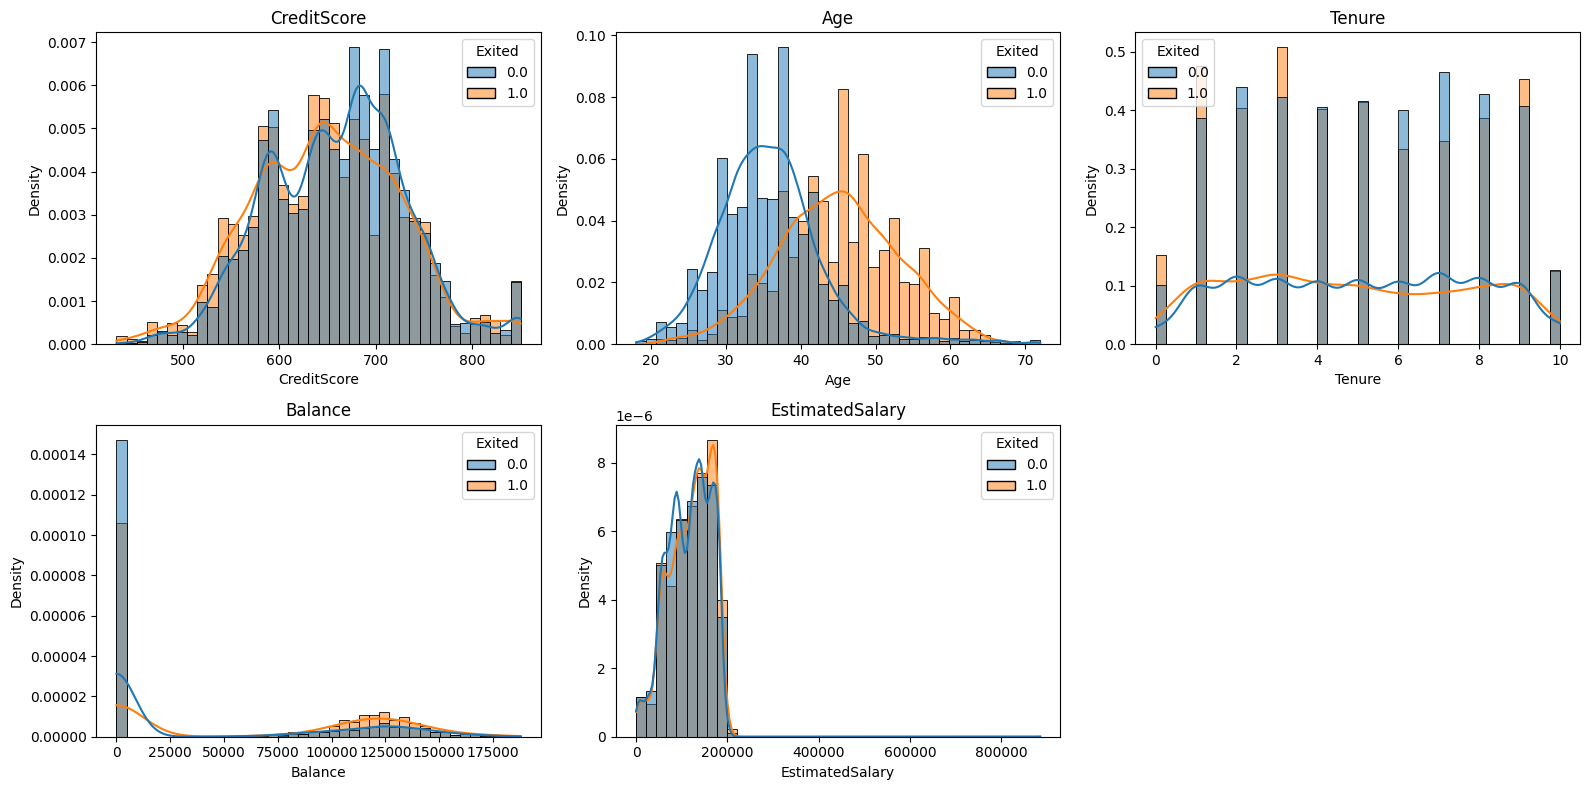

In [8]:
# Sonli o'zgaruvchilar: Exited bo'yicha taqsimot
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=train, x=c, hue='Exited', bins=40, kde=True, stat='density', common_norm=False, ax=ax)
    ax.set_title(c)
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

/tmp/ipykernel_14668/1505487633.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Exited', y=c, ax=ax, palette='Set2')
/tmp/ipykernel_14668/1505487633.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Exited', y=c, ax=ax, palette='Set2')
/tmp/ipykernel_14668/1505487633.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Exited', y=c, ax=ax, palette='Set2')
/tmp/ipykernel_14668/1505487633.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14

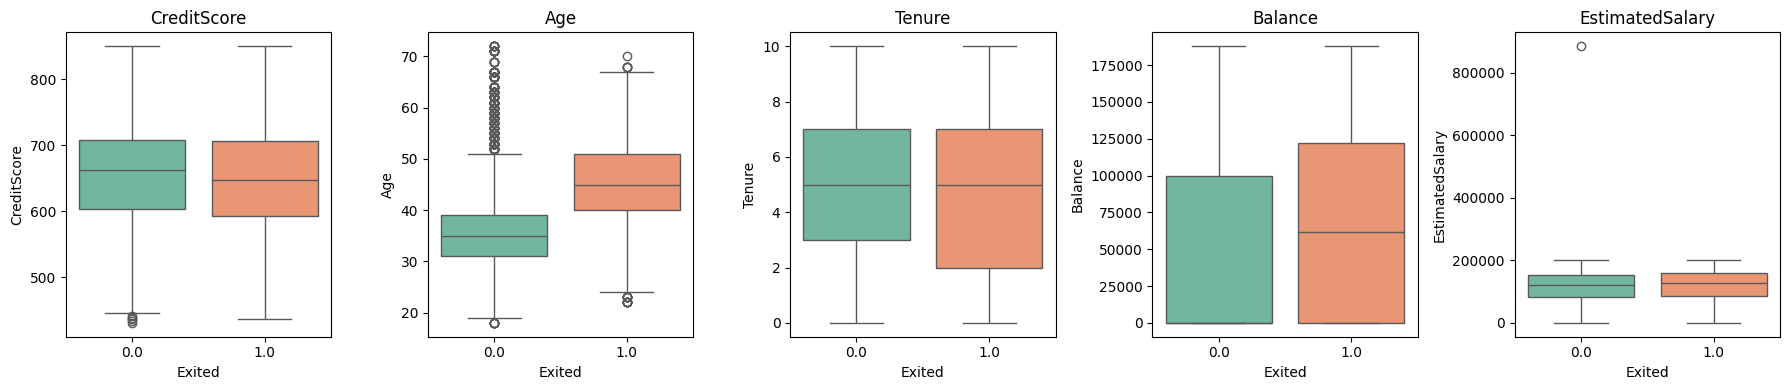

In [9]:
# Boxplot: chiquvchilarni ko'rish
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=train, x='Exited', y=c, ax=ax, palette='Set2')
    ax.set_title(c)
plt.tight_layout(); plt.show()

/tmp/ipykernel_14668/348740133.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate, x=c, y='Exited', ax=ax, palette='viridis')
/tmp/ipykernel_14668/348740133.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate, x=c, y='Exited', ax=ax, palette='viridis')
/tmp/ipykernel_14668/348740133.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rate, x=c, y='Exited', ax=ax, palette='viridis')
/tmp/ipykernel_14668/348740133.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.

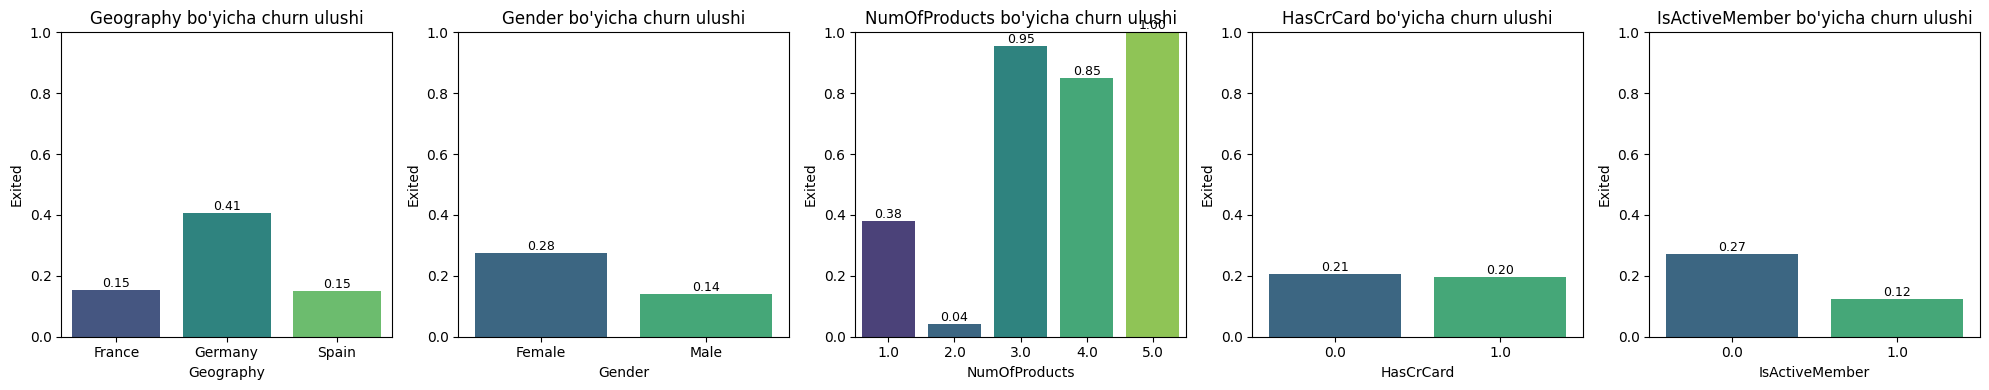

In [10]:
# Kategorik o'zgaruvchilar bo'yicha churn darajasi
cat_cols = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, cat_cols):
    rate = train.groupby(c).Exited.mean().reset_index()
    sns.barplot(data=rate, x=c, y='Exited', ax=ax, palette='viridis')
    ax.set_title(f'{c} bo\'yicha churn ulushi'); ax.set_ylim(0, 1)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

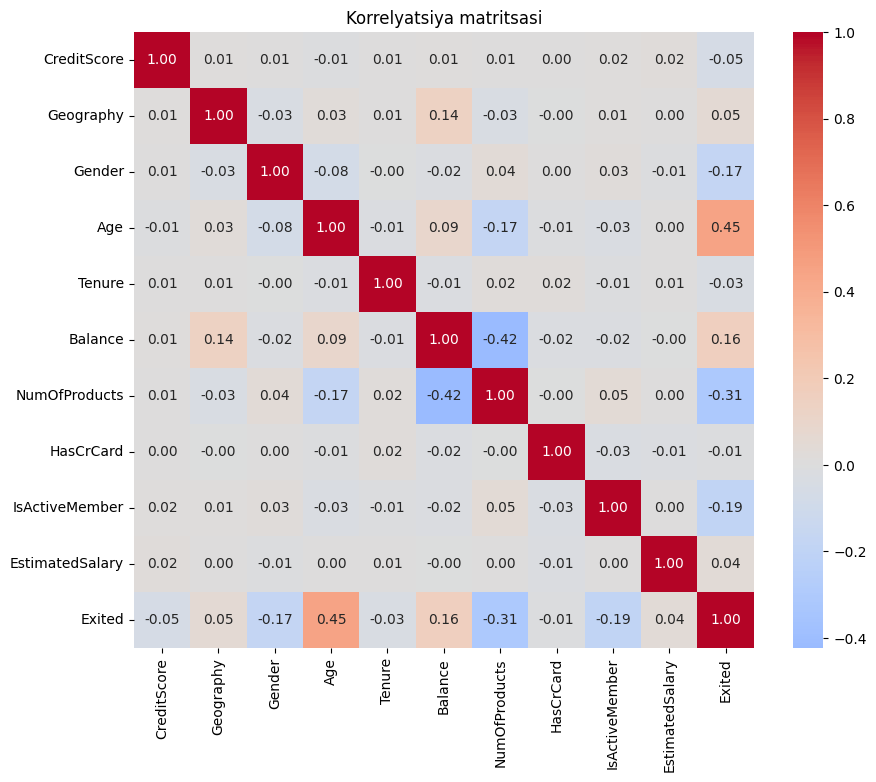

In [11]:
# Korrelyatsiya matritsasi
corr_df = train.drop(columns=['id', 'CustomerId', 'Surname']).copy()
corr_df['Geography'] = corr_df.Geography.astype('category').cat.codes
corr_df['Gender'] = (corr_df.Gender == 'Male').astype(int)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korrelyatsiya matritsasi'); plt.show()

/tmp/ipykernel_14668/855376385.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby('AgeGroup').Exited.mean().plot(kind='bar', ax=ax[0], color='tab:orange')


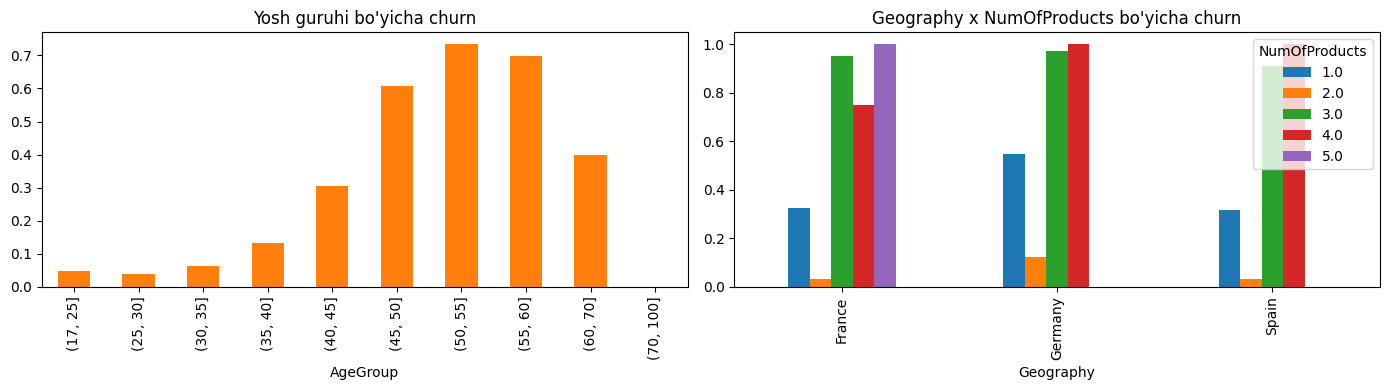

In [12]:
# Yosh guruhlari va Mahsulotlar soni bo'yicha churn
tmp = train.copy()
tmp['AgeGroup'] = pd.cut(tmp.Age, [17, 25, 30, 35, 40, 45, 50, 55, 60, 70, 100])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
tmp.groupby('AgeGroup').Exited.mean().plot(kind='bar', ax=ax[0], color='tab:orange')
ax[0].set_title('Yosh guruhi bo\'yicha churn')
pd.crosstab(tmp.Geography, tmp.NumOfProducts, values=tmp.Exited, aggfunc='mean').plot(kind='bar', ax=ax[1])
ax[1].set_title('Geography x NumOfProducts bo\'yicha churn')
plt.tight_layout(); plt.show()

## 3. Feature engineering

In [13]:
def make_features(tr, te):
    n = len(tr)
    df = pd.concat([tr.drop(columns='Exited'), te], ignore_index=True)
    df['Geography'] = df.Geography.astype('category').cat.codes
    df['Gender'] = (df.Gender == 'Male').astype(int)
    df['Surname_cnt'] = df.groupby('Surname').Surname.transform('count')
    df['Surname'] = df.Surname.astype('category').cat.codes
    df['CustCnt'] = df.groupby('CustomerId').CustomerId.transform('count')
    df['BalZero'] = (df.Balance == 0).astype(int)
    df['Bal_Sal'] = df.Balance / (df.EstimatedSalary + 1)
    df['Age_Prod'] = df.Age * df.NumOfProducts
    df['Cred_Age'] = df.CreditScore / df.Age
    df['Ten_Age'] = df.Tenure / df.Age
    df['Sal_Age'] = df.EstimatedSalary / df.Age
    df['Geo_Gender'] = df.Geography * 2 + df.Gender
    df['Active_Prod'] = df.IsActiveMember * 10 + df.NumOfProducts
    X = df.drop(columns=['id'])
    return X.iloc[:n].reset_index(drop=True), X.iloc[n:].reset_index(drop=True)

X, X_test = make_features(train, test)
y = train.Exited.astype(int).values
print(X.shape, X_test.shape)

(15000, 22) (10000, 22)


## 4. Cross-validation (5-fold)

In [18]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

SEED = 42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X, y))

def run_cv(name, fit_predict):
    oof = np.zeros(len(X)); pred = np.zeros(len(X_test)); models = []
    for i, (a, b) in enumerate(folds):
        m, p_val, p_te = fit_predict(X.iloc[a], y[a], X.iloc[b], y[b], X_test)
        oof[b] = p_val; pred += p_te / len(folds); models.append(m)
        print(f'[{name}] fold {i}: AUC = {roc_auc_score(y[b], p_val):.5f}')
    print(f'[{name}] OOF AUC = {roc_auc_score(y, oof):.5f}\n')
    return oof, pred, models

# ---- LightGBM
def fit_lgb(Xa, ya, Xb, yb, Xt):
    m = lgb.LGBMClassifier(objective='binary', learning_rate=0.03, num_leaves=15, min_child_samples=40,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
                           n_estimators=3000, random_state=SEED, verbose=-1)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], eval_metric='auc', callbacks=[lgb.early_stopping(150, verbose=False)])
    return m, m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1]

# ---- XGBoost
def fit_xgb(Xa, ya, Xb, yb, Xt):
    m = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=4, subsample=0.8,
                          colsample_bytree=0.7, min_child_weight=5, reg_lambda=5, eval_metric='auc',
                          early_stopping_rounds=150, random_state=SEED, tree_method='hist')
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m, m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1]

# ---- CatBoost
def fit_cat(Xa, ya, Xb, yb, Xt):
    m = CatBoostClassifier(iterations=3000, learning_rate=0.05, depth=6, l2_leaf_reg=5, eval_metric='AUC',
                           early_stopping_rounds=150, random_seed=SEED, verbose=False)
    m.fit(Xa, ya, eval_set=(Xb, yb))
    return m, m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1]

oof_lgb, pred_lgb, models_lgb = run_cv('LightGBM', fit_lgb)
oof_xgb, pred_xgb, models_xgb = run_cv('XGBoost', fit_xgb)
oof_cat, pred_cat, models_cat = run_cv('CatBoost', fit_cat)

[LightGBM] fold 0: AUC = 0.93670
[LightGBM] fold 1: AUC = 0.92860
[LightGBM] fold 2: AUC = 0.93217
[LightGBM] fold 3: AUC = 0.93176
[LightGBM] fold 4: AUC = 0.93507
[LightGBM] OOF AUC = 0.93276

[XGBoost] fold 0: AUC = 0.93741
[XGBoost] fold 1: AUC = 0.92844
[XGBoost] fold 2: AUC = 0.93146
[XGBoost] fold 3: AUC = 0.93211
[XGBoost] fold 4: AUC = 0.93485
[XGBoost] OOF AUC = 0.93283

[CatBoost] fold 0: AUC = 0.93741
[CatBoost] fold 1: AUC = 0.92879
[CatBoost] fold 2: AUC = 0.93228
[CatBoost] fold 3: AUC = 0.93327
[CatBoost] fold 4: AUC = 0.93671
[CatBoost] OOF AUC = 0.93362



## 5. Baholash grafiklari

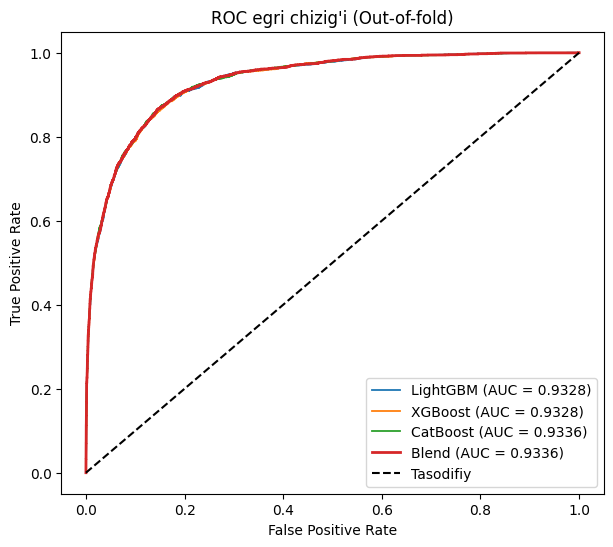

In [20]:
from sklearn.metrics import roc_curve

# ROC egri chizig'i (OOF) — barcha modellar
oofs = {'LightGBM': oof_lgb, 'XGBoost': oof_xgb, 'CatBoost': oof_cat}
# Blend: rank-average
from scipy.stats import rankdata
def rank_avg(arrs, w=None):
    r = np.average([rankdata(a) / len(a) for a in arrs], axis=0, weights=w)
    return r
oof_blend = rank_avg(list(oofs.values()))
oofs['Blend'] = oof_blend

plt.figure(figsize=(7, 6))
for k, v in oofs.items():
    fpr, tpr, _ = roc_curve(y, v)
    plt.plot(fpr, tpr, lw=2 if k == 'Blend' else 1.3, label=f'{k} (AUC = {roc_auc_score(y, v):.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Tasodifiy')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC egri chizig\'i (Out-of-fold)'); plt.legend(loc='lower right'); plt.show()

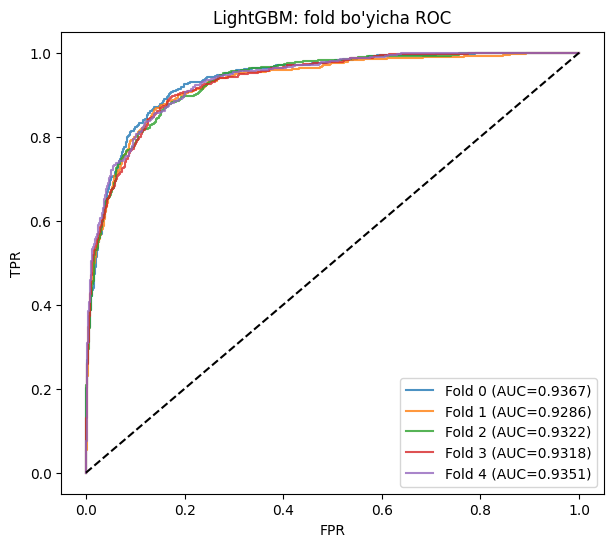

In [21]:
# Fold bo'yicha ROC (LightGBM)
plt.figure(figsize=(7, 6))
for i, (a, b) in enumerate(folds):
    fpr, tpr, _ = roc_curve(y[b], oof_lgb[b])
    plt.plot(fpr, tpr, alpha=.8, label=f'Fold {i} (AUC={roc_auc_score(y[b], oof_lgb[b]):.4f})')
plt.plot([0, 1], [0, 1], 'k--'); plt.legend(loc='lower right')
plt.title('LightGBM: fold bo\'yicha ROC'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.show()

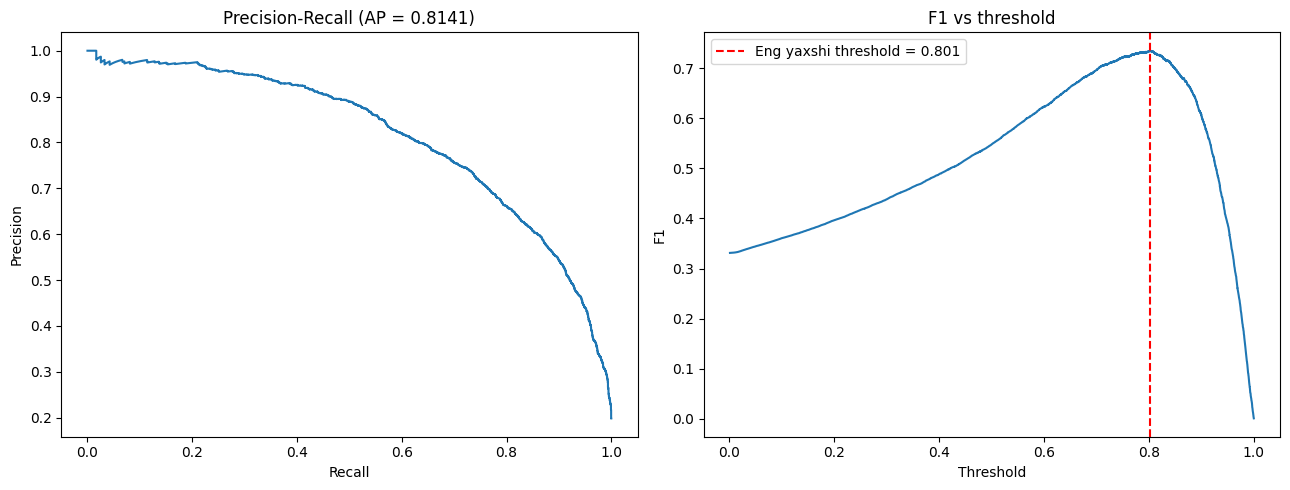

In [23]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Precision-Recall egri chizig'i va optimal threshold (F1)
prec, rec, thr = precision_recall_curve(y, oof_blend)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = f1[:-1].argmax(); best_thr = thr[best]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(rec, prec); ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precision')
ax[0].set_title(f'Precision-Recall (AP = {average_precision_score(y, oof_blend):.4f})')
ax[1].plot(thr, f1[:-1]); ax[1].axvline(best_thr, color='r', ls='--', label=f'Eng yaxshi threshold = {best_thr:.3f}')
ax[1].set_xlabel('Threshold'); ax[1].set_ylabel('F1'); ax[1].set_title('F1 vs threshold'); ax[1].legend()
plt.tight_layout(); plt.show()

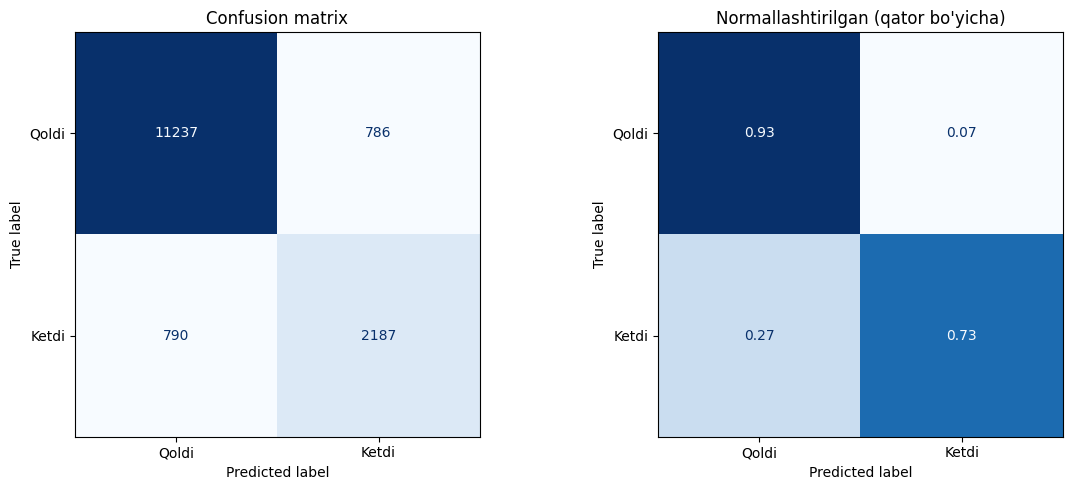

              precision    recall  f1-score   support

   Qoldi (0)       0.93      0.93      0.93     12023
   Ketdi (1)       0.74      0.73      0.74      2977

    accuracy                           0.89     15000
   macro avg       0.83      0.83      0.83     15000
weighted avg       0.89      0.89      0.89     15000



In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Confusion matrix + classification report (rank-blend OOF, F1-optimal threshold)
pred_lbl = (oof_blend >= best_thr).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_lbl), display_labels=['Qoldi', 'Ketdi']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')
ConfusionMatrixDisplay(confusion_matrix(y, pred_lbl, normalize='true'), display_labels=['Qoldi', 'Ketdi']).plot(ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
ax[1].set_title('Normallashtirilgan (qator bo\'yicha)')
plt.tight_layout(); plt.show()
print(classification_report(y, pred_lbl, target_names=['Qoldi (0)', 'Ketdi (1)']))

/tmp/ipykernel_14668/1005639546.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp, x='importance', y='feature', palette='viridis')


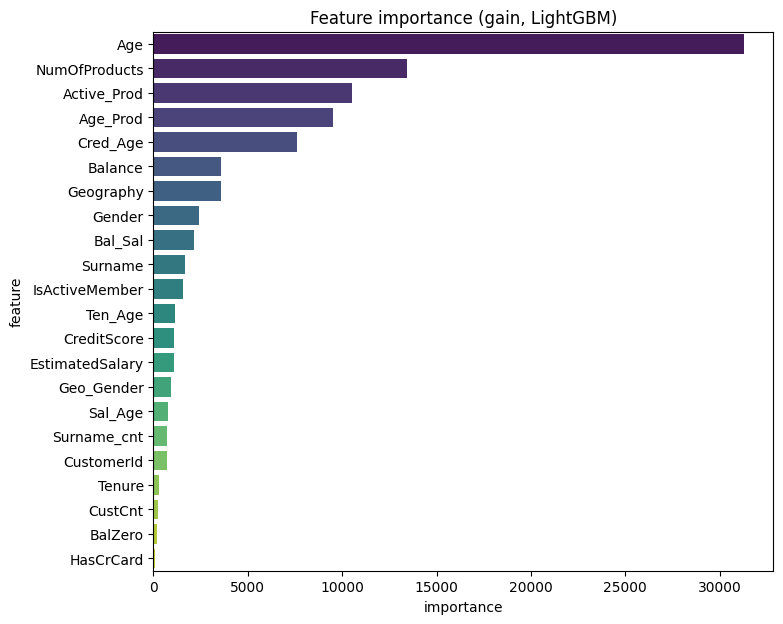

In [26]:
# Feature importance (LightGBM, foldlar o'rtachasi)
imp = pd.DataFrame({'feature': X.columns,
                    'importance': np.mean([m.booster_.feature_importance('gain') for m in models_lgb], axis=0)})
imp = imp.sort_values('importance', ascending=False)
plt.figure(figsize=(8, 7))
sns.barplot(data=imp, x='importance', y='feature', palette='viridis')
plt.title('Feature importance (gain, LightGBM)'); plt.show()

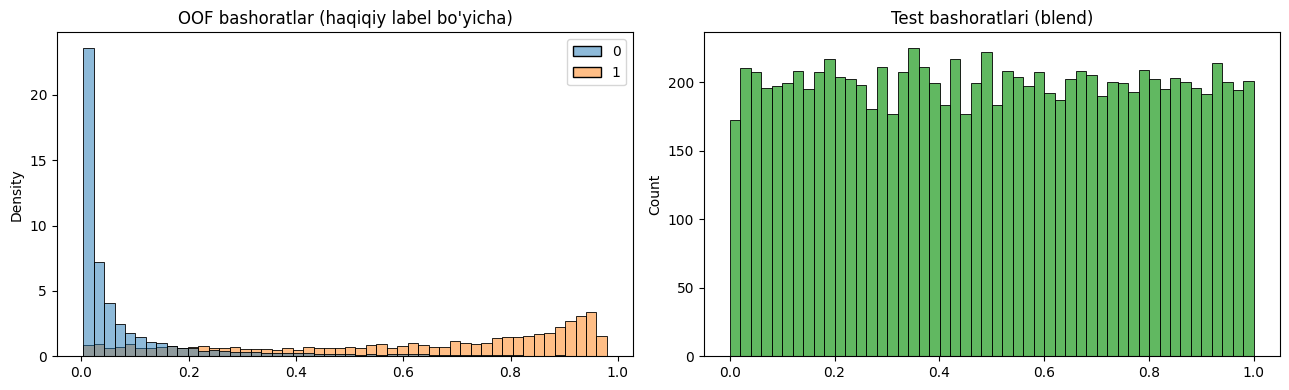

In [27]:
# Bashorat taqsimoti: train OOF va test
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(x=oof_lgb, hue=y, bins=50, stat='density', common_norm=False, ax=ax[0]); ax[0].set_title('OOF bashoratlar (haqiqiy label bo\'yicha)')
test_blend = rank_avg([pred_lgb, pred_xgb, pred_cat])
sns.histplot(test_blend, bins=50, ax=ax[1], color='tab:green'); ax[1].set_title('Test bashoratlari (blend)')
plt.tight_layout(); plt.show()

## 6. Submission

In [28]:
# Ehtimollik formati saqlanishi uchun: oddiy o'rtacha (AUC rank-blend bilan deyarli bir xil)
final = (pred_lgb + pred_xgb + pred_cat) / 3
print('OOF AUC (oddiy o\'rtacha):', round(roc_auc_score(y, (oof_lgb + oof_xgb + oof_cat) / 3), 5))

submission = pd.DataFrame({'id': test.id, 'Exited': final})
assert len(submission) == len(sub) and (submission.id.values == sub.id.values).all()
submission.to_csv('submission.csv', index=False)
print(submission.head())

try:
    from google.colab import files
    files.download('submission.csv')
except Exception:
    pass

OOF AUC (oddiy o'rtacha): 0.93356
      id    Exited
0  15000  0.061139
1  15001  0.160727
2  15002  0.042905
3  15003  0.157997
4  15004  0.007128


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>